In [7]:
from pathlib import Path

figs_dir = Path('results/figs')
figs_dir.mkdir(parents=True, exist_ok=True)
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# Plot style (kept close to plot.ipynb, cleaned)
rcpsize = 14
plt.rcParams['xtick.labelsize'] = rcpsize
plt.rcParams['ytick.labelsize'] = rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)

# Data config (English LLaMA results)
base = Path('results/santiago')
subtract_mean = 0
batch_shuffle = 0
take_last = 1
model = 'llama'
language = 'english'
n_files = 400
min_token_length = 37
mask = 2
k = 10
Nbits = 0
seeds = np.arange(5, dtype=int)
n_tokens = 1

def result_folder(seed: int) -> Path:
    return (
        base
        / f'subtract_mean_{subtract_mean}'
        / f'batch_shuffle_{batch_shuffle}'
        / f'take_last_{take_last}'
        / f'modelA_{model}'
        / f'modelB_{model}'
        / f'n_files_{n_files}'
        / f'min_token_length_{min_token_length}'
        / f'languageA_{language}'
        / f'mask_{mask}'
        / f'k_{k}'
        / f'Nbits_{Nbits}'
        / f'seed_{seed}'
    )

ab_per_seed = []
for seed in seeds:
    ab_path = result_folder(seed) / f'n_tokens_{n_tokens}_avg_0_AB.npy'
    if not ab_path.exists():
        raise FileNotFoundError(ab_path)
    ab_per_seed.append(np.load(ab_path))

ab_per_seed = np.stack(ab_per_seed, axis=0)  # [seed, layer, tau]
n_layers = ab_per_seed.shape[1]
n_loaded_tokens = ab_per_seed.shape[2]

print(f'Loaded AB arrays: {ab_per_seed.shape} (seed, layer, tau)')


Loaded AB arrays: (5, 32, 35) (seed, layer, tau)


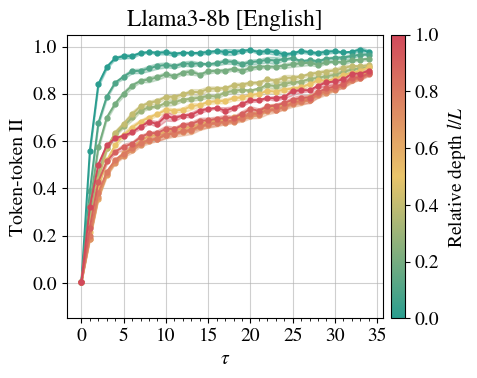

In [8]:
# Relative depths and corresponding layer indices (DeepSeek-like selection density)
relative_depths = np.array([0.001, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.999])
layer_ids = (relative_depths * n_layers).astype(int)
layer_ids = np.clip(layer_ids, 0, n_layers - 1)

depth_cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    'depth3_llama',
    ['#2A9D8F', '#E9C46A', '#D1495B'],
    N=256,
)
depth_norm = plt.Normalize(vmin=0.0, vmax=1.0)
depth_colors = depth_cmap(depth_norm(relative_depths))

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
x = np.arange(n_loaded_tokens)

for idx, (r, layer_id) in enumerate(zip(relative_depths, layer_ids)):
    mu_ab = ab_per_seed[:, layer_id, :].mean(axis=0)
    std_ab = ab_per_seed[:, layer_id, :].std(axis=0)
    ax.plot(
        x,
        mu_ab,
        linestyle='-',
        marker='o',
        ms=3.5,
        lw=1.4,
        color=depth_colors[idx],
    )
    ax.fill_between(x, mu_ab - std_ab, mu_ab + std_ab, alpha=0.35, color=depth_colors[idx])

ax.set_xlabel(r'$\tau$')
ax.set_ylabel('Token-token II')
ax.set_xticks(np.arange(0, n_loaded_tokens + 1, 5))
ax.set_xticks(np.arange(0, n_loaded_tokens + 1, 1), minor=True)
ax.grid(which='major', alpha=0.6)
ax.set_ylim(-0.15, 1.05)
ax.set_title('Llama3-8b [English]')

sm = plt.cm.ScalarMappable(cmap=depth_cmap, norm=depth_norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label(r'Relative depth $l/L$')
ticks = np.round(np.linspace(0.0, 1.0, 6), 2)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{t:.1f}' for t in ticks])

plt.show()


/tmp/ipykernel_2493958/2854522299.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.savefig(figs_dir / 'llama_token-token-II_english_vs_italian.pdf', dpi=200, bbox_inches='tight')
/home/acevedo/venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


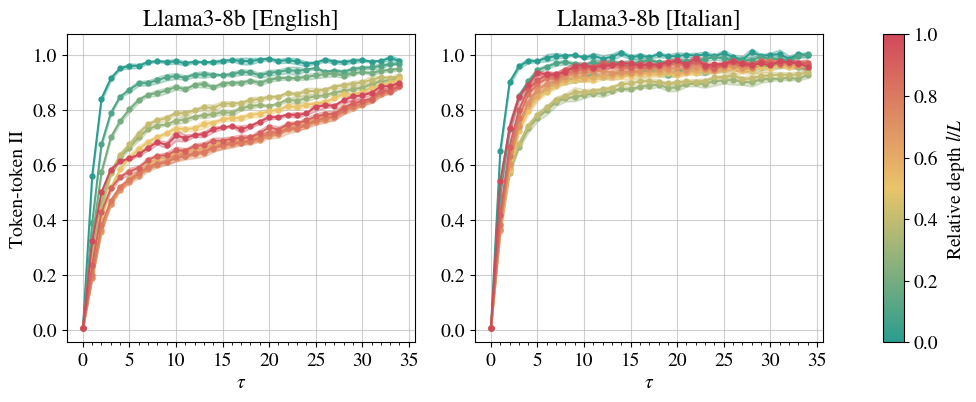

In [9]:
# Side-by-side Llama correlations in English and Italian
compare_languages = ['english', 'italian']

relative_depths = np.array([0.001, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.999])
depth_norm = plt.Normalize(vmin=0.0, vmax=1.0)
depth_colors = depth_cmap(depth_norm(relative_depths))

fig = plt.figure(figsize=(10.8, 4))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.06], wspace=0.25)
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1], sharey=ax0)
axes = [ax0, ax1]
cax = fig.add_subplot(gs[0, 2])

for ax, language in zip(axes, compare_languages):
    per_seed = []
    for seed in seeds:
        ab_path = (
            base
            / f'subtract_mean_{subtract_mean}'
            / f'batch_shuffle_{batch_shuffle}'
            / f'take_last_{take_last}'
            / f'modelA_{model}'
            / f'modelB_{model}'
            / f'n_files_{n_files}'
            / f'min_token_length_{min_token_length}'
            / f'languageA_{language}'
            / f'mask_{mask}'
            / f'k_{k}'
            / f'Nbits_{Nbits}'
            / f'seed_{seed}'
            / f'n_tokens_{n_tokens}_avg_0_AB.npy'
        )
        if not ab_path.exists():
            raise FileNotFoundError(ab_path)
        per_seed.append(np.load(ab_path))

    per_seed = np.stack(per_seed, axis=0)  # [seed, layer, tau]
    n_layers_lang = per_seed.shape[1]
    n_loaded_tokens_lang = per_seed.shape[2]
    layer_ids_lang = np.clip((relative_depths * n_layers_lang).astype(int), 0, n_layers_lang - 1)
    x = np.arange(n_loaded_tokens_lang)

    for idx, layer_id in enumerate(layer_ids_lang):
        mu_ab = per_seed[:, layer_id, :].mean(axis=0)
        std_ab = per_seed[:, layer_id, :].std(axis=0)
        ax.plot(x, mu_ab, linestyle='-', marker='o', ms=3.5, lw=1.4, color=depth_colors[idx])
        ax.fill_between(x, mu_ab - std_ab, mu_ab + std_ab, alpha=0.35, color=depth_colors[idx])

    ax.grid(which='major', alpha=0.6)
    ax.set_xlabel(r'$\tau$')
    ax.set_xticks(np.arange(0, n_loaded_tokens_lang + 1, 5))
    ax.set_xticks(np.arange(0, n_loaded_tokens_lang + 1, 1), minor=True)
    ax.set_title(f'Llama3-8b [{language.title()}]')

axes[0].set_ylabel('Token-token II')
sm = plt.cm.ScalarMappable(cmap=depth_cmap, norm=depth_norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r'Relative depth $l/L$')
ticks = np.round(np.linspace(0.0, 1.0, 6), 2)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{t:.1f}' for t in ticks])

fig.savefig(figs_dir / 'llama_token-token-II_english_vs_italian.pdf', dpi=200, bbox_inches='tight')
plt.show()
